# อะไรทำให้แอปบน App Store "ติดตลาด"
วิเคราะห์ข้อมูล Apple App Store 1.23 ล้านแอป ด้วย PySpark, SQL และ scikit-learn บน Databricks

**ข้อมูล:** [Kaggle: gauthamp10/apple-appstore-apps](https://www.kaggle.com/datasets/gauthamp10/apple-appstore-apps) (21 คอลัมน์, ไฟล์ลงวันที่ 14 ต.ค. 2021 ดูหมายเหตุเรื่องวันอ้างอิงในข้อ 12)

**คำถามหลัก:** แอปแบบไหนได้รับความนิยม (วัดจากจำนวนรีวิว) และตลาดนี้เหลื่อมล้ำแค่ไหน

## นิยามที่ใช้ทั้ง notebook
| คำ | ความหมาย |
|---|---|
| ติดตลาด (hit) | แอปที่มีรีวิวมากกว่า 1,000 รีวิว |
| แอปร้าง (zombie) | แอปที่ไม่ได้อัปเดตเกิน 730 วัน นับถึงวันที่เก็บข้อมูล |
| วันอ้างอิง | วันที่ `Updated` มากที่สุดในข้อมูล (ไม่ใช่วันนี้ เพราะข้อมูลเป็น snapshot) |
| ช่วงปีที่ใช้ | 2008-2021 (ปี 2022 ข้อมูลไม่ครบปี และปี 2021 ก็มีข้อมูลถึงราว ต.ค. เท่านั้น) |

## สารบัญ
0. เตรียมข้อมูลและสร้างตัวแปรใหม่
1. ตรวจคุณภาพข้อมูล
2. ตลาดเหลื่อมล้ำแค่ไหน
3. หมวดหมู่: ติดตลาดง่ายและแอปร้าง
4. ตลาดเปลี่ยนไปตามเวลา
5. ราคาและแอปฟรี
6. ขนาดแอป
7. นักพัฒนา: รายเดี่ยวและโรงงานแอป
8. การอัปเดตกับความนิยม
9. โมเดลทำนายแอปที่ติดตลาด
10. ทดสอบสมมติฐานทางสถิติ
11. ตารางสรุปสำหรับทำเว็บ
12. ข้อจำกัดของการวิเคราะห์

## คู่มือสำหรับทำสไลด์
ตารางนี้บอกว่าสไลด์แต่ละหน้าใช้ผลจากหัวข้อไหนใน notebook ส่วนสไลด์ที่เขียนว่า **รอผล** จะเพิ่มเป็นหัวข้อใหม่ภายหลัง

| สไลด์ | เรื่อง | ดูหัวข้อ | ไฟล์ใน `results/` |
|---|---|---|---|
| 3–4 | Dataset, เครื่องมือ, pipeline | 0 | – |
| 5 | นิยาม hit / zombie | ตารางนิยามด้านบน | – |
| 6 | คุณภาพข้อมูล | 1 | `quality.csv` |
| 7 | ตลาดเหลื่อมล้ำ | 2 | `Long Tail Review.csv`, `review.csv` |
| 8 | หมวดหมู่และแอปร้าง | 3 | `best category.csv`, `zombieapp.csv` |
| 9 | ตลาดตามเวลา | 4 | `ratio per year.csv`, `timeline open app free.paid.csv` |
| 10 | ราคา | 5 | `free.paid.csv`, `price psycho.csv` |
| 11 | ขนาดแอป | 6 | `fatapps.csv`, `fatapp catagory.csv` |
| 12 | นักพัฒนา | 7 | `factory vs indie.csv`, `top 15 dev most app.csv` |
| 13 | นักพัฒนาที่ hit ซ้ำ | รอผล | – |
| 14 | การอัปเดต | 8 | `is update effect review.csv`, `good app vs bad app.csv` |
| 15 | เลขเวอร์ชันและดาวที่เชื่อได้ | รอผล | – |
| 16–17 | โมเดลทำนาย hit และ baseline | 9 (baseline รอผล) | – |
| 18 | ทดสอบสถิติ | 10 | – |
| 19 | จัดกลุ่มแอปด้วย Spark MLlib | รอผล | – |
| 20, 22 | ข้อมูลผิดตรงไหน, ข้อจำกัด | 12 | – |
| 21 | Demo เว็บ | 11 | `cube for web.csv` |

## 0. เตรียมข้อมูลและสร้างตัวแปรใหม่
**ทำอะไร:** อ่านตารางที่อัปโหลดไว้ ตัดแถวซ้ำตาม `App_Id` แล้วสร้างคอลัมน์ที่ใช้วิเคราะห์ต่อ

| ตัวแปรใหม่ | วิธีคำนวณ |
|---|---|
| `size_mb` | `Size_Bytes` หาร 1,000,000 |
| `release_year` | ปีของ `Released` |
| `age_days` | วันอ้างอิง ลบ `Released` |
| `days_since_update` | วันอ้างอิง ลบ `Updated` |
| `is_zombie` | 1 ถ้า `days_since_update` มากกว่า 730 |
| `has_website` | 1 ถ้า `Developer_Website` ไม่ใช่ null |
| `ios_ver` | เลขเวอร์ชันหลักของ iOS ที่ต้องใช้ เช่น `5.1.1` เป็น 5 |
| `dev_app_count` | จำนวนแอปทั้งหมดของนักพัฒนาคนเดียวกัน |

ผลลัพธ์ถูกเก็บเป็น view ชื่อ `apps` ที่เซลล์ SQL ทุกอันใช้ต่อ

In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

T = "workspace.default.apple_app_data"
raw = spark.table(T)

ref_date = raw.agg(F.max("Updated")).first()[0]
print("ref_date:", ref_date)

clean = (
    raw.dropDuplicates(["App_Id"])
    .withColumn("size_mb", F.col("Size_Bytes") / 1e6)
    .withColumn("release_year", F.year("Released"))
    .withColumn("age_days", F.datediff(F.lit(ref_date), F.col("Released")))
    .withColumn("days_since_update", F.datediff(F.lit(ref_date), F.col("Updated")))
    .withColumn("is_zombie", (F.col("days_since_update") > 730).cast("int"))
    .withColumn("has_website", F.col("Developer_Website").isNotNull().cast("int"))
    .withColumn("ios_ver", F.regexp_extract("Required_IOS_Version", r"^(\d+)", 1).cast("int"))
    .withColumn("dev_app_count", F.count("*").over(Window.partitionBy("DeveloperId")))
)
clean.createOrReplaceTempView("apps")
print("rows:", clean.count())

ref_date: 2022-04-09 07:00:00
rows: 1230376


## 1. ตรวจคุณภาพข้อมูล
**ทำอะไร:** นับค่า null ทุกคอลัมน์ นับแอปที่ไม่มีรีวิว และตรวจว่าคะแนนเวอร์ชันปัจจุบันต่างจากคะแนนรวมหรือไม่

**วัดยังไง:** นับจำนวนแถวที่เข้าเงื่อนไข แล้วเทียบเป็นเปอร์เซ็นต์ของทั้งหมด

**ที่พบ:**
- null จริงมีมากแค่ `Developer_Website` (ราว 52%) ซึ่งหมายถึงนักพัฒนาไม่มีเว็บไซต์ จึงใช้เป็นตัวแปรได้
- แอป 55.6% ไม่มีรีวิวเลย (เก็บเป็น 0 ไม่ใช่ null) ดังนั้นการวิเคราะห์ดาวต้องกรอง `Reviews > 0`
- `Current_Version_Score` ไม่ต่างจาก `Average_User_Rating` ในแอปที่มีรีวิวเวอร์ชันปัจจุบันตั้งแต่ 50 ขึ้นไป จึงสร้างตัวแปร "แนวโน้มคะแนน" ไม่ได้

In [0]:
display(raw.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in raw.columns]))

App_Id,App_Name,AppStore_Url,Primary_Genre,Content_Rating,Size_Bytes,Required_IOS_Version,Released,Updated,Version,Price,Currency,Free,DeveloperId,Developer,Developer_Url,Developer_Website,Average_User_Rating,Reviews,Current_Version_Score,Current_Version_Reviews
0,0,0,0,0,224,0,3,0,0,490,0,0,0,0,1109,643988,0,0,0,0


In [0]:
%sql
SELECT COUNT(*) AS total,
       SUM(CASE WHEN Reviews = 0 THEN 1 ELSE 0 END) AS no_reviews,
       ROUND(100.0 * SUM(CASE WHEN Reviews = 0 THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_no_reviews
FROM apps;

total,no_reviews,pct_no_reviews
1230376,684320,55.6


In [0]:
%sql
SELECT COUNT(*) AS total,
       SUM(CASE WHEN Current_Version_Score <> Average_User_Rating THEN 1 ELSE 0 END) AS differ
FROM apps
WHERE Current_Version_Reviews >= 50;

total,differ
90241,1


In [0]:
print("apps updated within 90 days of ref_date:", clean.where("days_since_update <= 90").count())

apps updated within 90 days of ref_date: 53


## 2. ตลาดเหลื่อมล้ำแค่ไหน
**ทำอะไร:** ดูว่ารีวิวทั้งหมดในตลาดกระจุกอยู่กับแอปกลุ่มไหน

**วัดยังไง:**
1. เรียงแอปจากรีวิวมากไปน้อย แล้วคำนวณสัดส่วนรีวิวที่แอป 1% และ 10% บนสุดถือ
2. วาด **Lorenz curve** แกนนอนคือสัดส่วนแอป (เรียงจากรีวิวน้อยไปมาก) แกนตั้งคือสัดส่วนรีวิวสะสม เส้นประคือกรณีที่ทุกแอปได้รีวิวเท่ากัน
3. คำนวณ **Gini** จากพื้นที่ใต้เส้น Lorenz (0 = เท่ากันหมด, 1 = แอปเดียวถือทุกอย่าง)

**อ่านผล:** เส้นยิ่งโค้งห่างจากเส้นประ Gini ยิ่งสูง ตลาดยิ่งกระจุกตัว

**ข้อควรระวัง:** วัดจากจำนวนรีวิว ไม่ใช่จำนวนผู้ใช้หรือยอดดาวน์โหลด แอปที่ไม่มีรีวิวไม่ได้แปลว่าไม่มีผู้ใช้

In [0]:
%sql
WITH r AS (
  SELECT Reviews, PERCENT_RANK() OVER (ORDER BY Reviews DESC) AS pct FROM apps
)
SELECT ROUND(SUM(CASE WHEN pct <= 0.01 THEN Reviews END) / SUM(Reviews) * 100, 1) AS top1pct_share,
       ROUND(SUM(CASE WHEN pct <= 0.10 THEN Reviews END) / SUM(Reviews) * 100, 1) AS top10pct_share
FROM r;

top1pct_share,top10pct_share
95.8,99.8


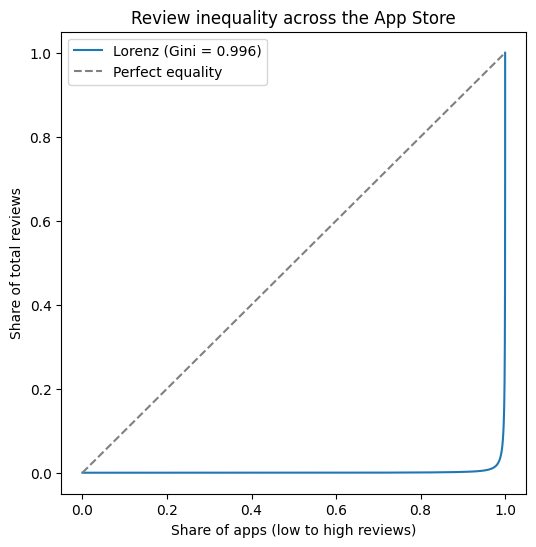

In [0]:
import numpy as np
import matplotlib.pyplot as plt

rev = np.sort(clean.select("Reviews").toPandas()["Reviews"].fillna(0).values)
cum = np.cumsum(rev) / rev.sum()
x = np.arange(1, len(rev) + 1) / len(rev)
gini = 1 - 2 * np.trapezoid(cum, x)

plt.figure(figsize=(6, 6))
plt.plot(x, cum, label=f"Lorenz (Gini = {gini:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect equality")
plt.xlabel("Share of apps (low to high reviews)")
plt.ylabel("Share of total reviews")
plt.title("Review inequality across the App Store")
plt.legend()
plt.show()

## 3. หมวดหมู่: ติดตลาดง่ายและแอปร้าง
**ทำอะไร:** เปรียบเทียบแต่ละ `Primary_Genre` ด้วยสามตัวชี้วัด

| ตัวชี้วัด | วิธีคำนวณ |
|---|---|
| `pct_any_review` | แอปที่มีรีวิวอย่างน้อย 1 รายการ หารจำนวนแอปในหมวด |
| `pct_hit` | แอปที่มีรีวิวเกิน 1,000 หารจำนวนแอปในหมวด |
| `pct_zombie` | แอปที่ไม่อัปเดตเกิน 2 ปี หารจำนวนแอปในหมวด |

**อ่านผล:** หมวดที่ `pct_hit` สูงและ `pct_zombie` ต่ำคือหมวดที่แอปมีโอกาสอยู่รอดและดังมากกว่า ให้ดูคอลัมน์ `apps` ควบคู่เสมอ เพราะหมวดเล็กมากทำให้เปอร์เซ็นต์แกว่งง่าย

In [0]:
%sql
SELECT Primary_Genre, COUNT(*) AS apps,
       ROUND(100.0 * AVG(CASE WHEN Reviews > 0 THEN 1 ELSE 0 END), 1) AS pct_any_review,
       ROUND(100.0 * AVG(CASE WHEN Reviews > 1000 THEN 1 ELSE 0 END), 2) AS pct_hit
FROM apps
WHERE release_year <= 2021
GROUP BY Primary_Genre
ORDER BY pct_hit DESC;

Primary_Genre,apps,pct_any_review,pct_hit
Weather,3563,66.7,7.75
Graphics & Design,2781,35.2,4.89
Games,193700,64.0,4.66
Photo & Video,25957,62.4,4.47
Finance,44984,51.9,3.43
News,20423,40.1,2.63
Entertainment,53139,51.7,2.36
Social Networking,25428,47.7,2.13
Book,11472,53.4,1.92
Reference,18615,53.9,1.82


In [0]:
%sql
SELECT Primary_Genre, COUNT(*) AS apps,
       ROUND(100.0 * AVG(is_zombie), 1) AS pct_zombie
FROM apps
GROUP BY Primary_Genre
HAVING COUNT(*) >= 1000
ORDER BY pct_zombie DESC;

Primary_Genre,apps,pct_zombie
Stickers,12407,65.6
Games,193749,58.7
Photo & Video,25957,55.7
Reference,18615,52.2
Music,29898,51.2
Book,11472,51.2
Entertainment,53147,50.5
Education,119174,46.2
Navigation,12636,45.4
Travel,43726,43.9


## 4. ตลาดเปลี่ยนไปตามเวลา
**ทำอะไร:** ดูจำนวนแอปที่เปิดตัวแต่ละปี แยกแอปฟรีและเสียเงิน และดูสัดส่วนแอปที่ติดตลาดของแต่ละรุ่นปี

**วัดยังไง:** นับแอปตาม `release_year` และ `Free` และคำนวณ `pct_hit` ของแต่ละรุ่นปี

**ข้อควรระวัง:** แอปรุ่นใหม่มีเวลาสะสมรีวิวน้อยกว่าโดยธรรมชาติ ตัวเลขของปี 2020-2021 จึงต่ำกว่ารุ่นเก่าส่วนหนึ่งเพราะเหตุนี้ ไม่ได้แปลว่าคุณภาพแอปลดลงทั้งหมด

In [0]:
%sql
SELECT release_year, Free, COUNT(*) AS apps
FROM apps
WHERE release_year BETWEEN 2008 AND 2021
GROUP BY release_year, Free
ORDER BY release_year;

release_year,Free,apps
2008,true,294
2008,false,358
2009,true,2599
2009,false,1782
2010,false,3538
2010,true,7411
2011,true,13857
2011,false,5620
2012,false,5992
2012,true,21953


In [0]:
%sql
SELECT release_year, COUNT(*) AS apps,
       ROUND(100.0 * AVG(CASE WHEN Reviews > 0 THEN 1 ELSE 0 END), 1) AS pct_any_review,
       ROUND(100.0 * AVG(CASE WHEN Reviews > 1000 THEN 1 ELSE 0 END), 2) AS pct_hit
FROM apps
WHERE release_year BETWEEN 2008 AND 2021
GROUP BY release_year
ORDER BY release_year;

release_year,apps,pct_any_review,pct_hit
2008,652,90.6,9.97
2009,4381,95.7,11.57
2010,10949,89.4,7.58
2011,19477,77.2,6.33
2012,27945,75.9,5.31
2013,39427,69.1,4.04
2014,55321,63.4,3.1
2015,78661,55.9,2.54
2016,120352,51.3,2.0
2017,126356,49.7,2.12


## 5. ราคาและแอปฟรี
**ทำอะไร:** ดูว่านักพัฒนาตั้งราคาที่จุดไหนมากที่สุด และแอปฟรีต่างจากแอปเสียเงินอย่างไร

**วัดยังไง:**
- นับจำนวนแอปในแต่ละราคา (เฉพาะสกุล USD, ราคา 0-20 ดอลลาร์)
- เปรียบเทียบจำนวนรีวิวและดาวเฉลี่ยของแอปฟรีกับเสียเงิน เฉพาะแอปที่มีรีวิว โดยรายงานทั้งค่าเฉลี่ยและค่ามัธยฐาน

**อ่านผล:** ค่าเฉลี่ยรีวิวถูกดึงขึ้นด้วยแอปดังไม่กี่ตัว ค่ามัธยฐานสะท้อนแอปทั่วไปมากกว่า จึงต้องดูคู่กัน

In [0]:
%sql
SELECT Price, COUNT(*) AS apps
FROM apps
WHERE Price > 0 AND Price <= 20 AND Currency = 'USD'
GROUP BY Price
ORDER BY apps DESC
LIMIT 20;

Price,apps
0.99,33813
1.99,19905
2.99,13246
4.99,8817
3.99,6677
9.99,3776
6.99,2919
5.99,2118
7.99,1496
19.99,1489


In [0]:
%sql
SELECT Free, COUNT(*) AS apps,
       ROUND(AVG(Reviews), 1) AS avg_reviews,
       percentile_approx(Reviews, 0.5) AS median_reviews,
       ROUND(AVG(Average_User_Rating), 3) AS avg_rating
FROM apps
WHERE Reviews > 0
GROUP BY Free;

Free,apps,avg_reviews,median_reviews,avg_rating
false,49317,190.1,4,3.731
true,496739,2026.9,4,4.059


## 6. ขนาดแอป
**ทำอะไร:** ดูว่าแอปใหญ่ขึ้นตามปีหรือไม่ ขนาดต่างกันตามหมวดอย่างไร และขนาดสัมพันธ์กับการติดตลาดหรือไม่

**วัดยังไง:**
- ค่าเฉลี่ยและมัธยฐานของ `size_mb` ตามปีและตามหมวด
- แบ่งขนาดเป็น 5 ช่วง (ต่ำกว่า 10, 10-50, 50-100, 100-500, 500 MB ขึ้นไป) แล้วคำนวณ `pct_hit` ของแต่ละช่วง

**อ่านผล:** ใช้มัธยฐานเป็นหลัก เพราะแอปขนาดใหญ่ผิดปกติดึงค่าเฉลี่ยขึ้น ขนาดสัมพันธ์กับการติดตลาด แต่ไม่ได้พิสูจน์ว่าการทำแอปให้ใหญ่ขึ้นทำให้ดัง

In [0]:
%sql
SELECT release_year,
       ROUND(AVG(size_mb), 1) AS avg_size_mb,
       ROUND(percentile_approx(size_mb, 0.5), 1) AS median_size_mb
FROM apps
WHERE release_year BETWEEN 2008 AND 2021 AND size_mb > 0
GROUP BY release_year
ORDER BY release_year;

release_year,avg_size_mb,median_size_mb
2008,44.9,20.3
2009,54.8,24.2
2010,65.3,30.6
2011,68.8,29.0
2012,66.2,31.3
2013,65.5,32.6
2014,62.6,29.8
2015,70.2,33.2
2016,70.4,35.5
2017,75.4,41.7


In [0]:
%sql
SELECT Primary_Genre, ROUND(percentile_approx(size_mb, 0.5), 1) AS median_size_mb
FROM apps
WHERE size_mb > 0
GROUP BY Primary_Genre
ORDER BY median_size_mb DESC;

Primary_Genre,median_size_mb
Games,88.4
Travel,53.0
Health & Fitness,48.5
Shopping,46.9
Social Networking,46.2
Food & Drink,44.8
Finance,42.6
Book,42.2
Magazines & Newspapers,42.0
Sports,41.4


In [0]:
%sql
SELECT CASE WHEN size_mb IS NULL THEN 'unknown'
            WHEN size_mb < 10  THEN '1) <10 MB'
            WHEN size_mb < 50  THEN '2) 10-50 MB'
            WHEN size_mb < 100 THEN '3) 50-100 MB'
            WHEN size_mb < 500 THEN '4) 100-500 MB'
            ELSE '5) 500+ MB' END AS size_bucket,
       COUNT(*) AS apps,
       ROUND(100.0 * AVG(CASE WHEN Reviews > 1000 THEN 1 ELSE 0 END), 2) AS pct_hit
FROM apps
WHERE release_year BETWEEN 2008 AND 2021
GROUP BY 1
ORDER BY 1;

size_bucket,apps,pct_hit
1) <10 MB,141390,0.32
2) 10-50 MB,543132,0.89
3) 50-100 MB,315118,1.85
4) 100-500 MB,215906,5.43
5) 500+ MB,14560,8.96
unknown,209,20.1


## 7. นักพัฒนา: รายเดี่ยวและโรงงานแอป
**ทำอะไร:** แบ่งนักพัฒนาตามจำนวนแอปที่ตัวเองมี แล้วเปรียบเทียบผลงานของแต่ละกลุ่ม

**วัดยังไง:** แบ่งกลุ่มจาก `dev_app_count` เป็น 1 แอป, 2-10, 11-100 และมากกว่า 100 แอป จากนั้นดูจำนวนรีวิวเฉลี่ย ค่ามัธยฐาน และดาวเฉลี่ย (เฉพาะแอปที่มีรีวิว) พร้อมรายชื่อนักพัฒนา 15 อันดับที่มีแอปมากสุด

**อ่านผล:** นักพัฒนารายใหญ่หลายรายมีรีวิวเฉลี่ยใกล้ 0 ซึ่งบ่งว่าอาจเป็นผู้ผลิตแอปแบรนด์ให้ลูกค้าจำนวนมาก (ข้อสันนิษฐาน ยังไม่ได้ตรวจชื่อแอปทีละตัว)

In [0]:
%sql
SELECT CASE WHEN dev_app_count = 1 THEN '1 app (indie)'
            WHEN dev_app_count <= 10 THEN '2-10 apps'
            WHEN dev_app_count <= 100 THEN '11-100 apps'
            ELSE '100+ apps (factory)' END AS dev_size,
       COUNT(*) AS apps,
       ROUND(AVG(Reviews), 1) AS avg_reviews,
       percentile_approx(Reviews, 0.5) AS median_reviews,
       ROUND(AVG(CASE WHEN Reviews > 0 THEN Average_User_Rating END), 3) AS avg_rating
FROM apps
GROUP BY 1
ORDER BY apps;

dev_size,apps,avg_reviews,median_reviews,avg_rating
100+ apps (factory),82374,539.1,0,3.842
11-100 apps,324582,781.5,0,3.806
1 app (indie),350097,686.6,0,4.32
2-10 apps,473323,1009.4,0,4.007


In [0]:
%sql
SELECT Developer, COUNT(*) AS apps, ROUND(AVG(Reviews), 1) AS avg_reviews
FROM apps
GROUP BY Developer
ORDER BY apps DESC
LIMIT 15;

Developer,apps,avg_reviews
ChowNow,3966,14.2
Touch2Success,1649,0.0
Alexander Velimirovic,1506,0.0
"MINDBODY, Incorporated",1247,1.1
Phorest,1131,3.0
OFFLINE MAP TRIP GUIDE LTD,1022,0.1
Magzter Inc.,928,6.1
ASK Video,781,0.1
RAPID ACCELERATION INDIA PRIVATE LIMITED,733,4.6
Nonlinear Educating Inc.,555,0.8


## 8. การอัปเดตกับความนิยม
**ทำอะไร:** ดูว่าแอปที่อัปเดตล่าสุดไม่นานมีโอกาสได้รีวิวและติดตลาดมากกว่าหรือไม่

**วัดยังไง:** แบ่งแอปตามช่วงเวลาตั้งแต่อัปเดตล่าสุด (ภายใน 3 เดือน, 3-12 เดือน, 1-2 ปี, เกิน 2 ปี) แล้วเทียบ `pct_any_review` และ `pct_hit` เพื่อไม่ให้อายุแอปมาปนผล เลือกเฉพาะแอปที่เปิดตัวปี 2016-2018

**อ่านผล:** แอปที่อัปเดตไม่นานติดตลาดมากกว่าอย่างชัดเจน แต่แปลได้สองทาง คือการอัปเดตช่วยให้ดัง หรือแอปที่ดังมีรายได้จึงอัปเดตต่อ ข้อมูล snapshot นี้แยกสองทางไม่ได้ กลุ่ม "ภายใน 3 เดือน" ไม่มีแอปเลย ซึ่งอาจแปลว่าวันอ้างอิงมาจากแอปไม่กี่ตัว

In [0]:
%sql
SELECT CASE WHEN days_since_update <= 90  THEN '1) within 3 months'
            WHEN days_since_update <= 365 THEN '2) 3-12 months'
            WHEN days_since_update <= 730 THEN '3) 1-2 years'
            ELSE '4) over 2 years' END AS last_update,
       COUNT(*) AS apps,
       ROUND(100.0 * AVG(CASE WHEN Reviews > 0 THEN 1 ELSE 0 END), 1) AS pct_any_review,
       ROUND(100.0 * AVG(CASE WHEN Reviews > 1000 THEN 1 ELSE 0 END), 2) AS pct_hit
FROM apps
WHERE release_year BETWEEN 2016 AND 2018
GROUP BY 1
ORDER BY 1;

last_update,apps,pct_any_review,pct_hit
2) 3-12 months,72591,60.0,6.76
3) 1-2 years,60846,52.1,2.3
4) over 2 years,248330,44.7,0.7


## 9. โมเดลทำนายแอปที่ติดตลาด
**ทำอะไร:** สร้างโมเดลทำนายว่าแอปจะมีรีวิวเกิน 1,000 หรือไม่ จากลักษณะของแอป แล้วดูว่าปัจจัยไหนช่วยทำนายได้มากที่สุด

| หัวข้อ | รายละเอียด |
|---|---|
| เป้าหมาย | `Reviews > 1000` (ติดตลาดหรือไม่) |
| ตัวแปรต้น | หมวด, ฟรี/เสียเงิน, ราคา, ขนาด, มีเว็บไซต์, iOS ขั้นต่ำ, อายุแอป, จำนวนแอปของนักพัฒนา |
| ข้อมูล | สุ่ม 25% ของแอป แบ่ง train 80% และ test 20% แบบรักษาสัดส่วนคลาส |
| โมเดล | Histogram Gradient Boosting (scikit-learn) |
| ตัววัดโมเดล | **AUC** เพราะแอปที่ติดตลาดมีแค่ราว 2% การวัดด้วย accuracy จะหลอกตา (ตอบ "ไม่ติด" ทุกแอปก็ได้ 98%) |
| ตัววัดความสำคัญ | **Permutation importance** สลับค่าของตัวแปรหนึ่งแล้วดูว่า AUC ตกเท่าไร ตกมากแปลว่าสำคัญมาก |

**หมายเหตุ:** `age_days` ต้องอยู่ในโมเดล ไม่งั้นโมเดลจะเรียนรู้แค่ "แอปเก่ามีเวลาสะสมรีวิวนาน"

**ข้อควรระวัง:** ความสำคัญของตัวแปรคือความสามารถในการ **ทำนาย** ไม่ใช่ **สาเหตุ** และตัวแปรที่สัมพันธ์กัน (เช่น อายุแอปกับ iOS ขั้นต่ำ) จะแบ่งความสำคัญกัน

In [0]:
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

cols = ["Primary_Genre", "Free", "Price", "size_mb", "has_website",
        "ios_ver", "age_days", "dev_app_count", "Reviews"]
pdf = (clean.select(*cols).where("age_days IS NOT NULL")
       .sample(fraction=0.25, seed=42).toPandas())

pdf["y"] = (pdf["Reviews"] > 1000).astype(int)
pdf["Free"] = pdf["Free"].astype(int)
pdf["Primary_Genre"] = pdf["Primary_Genre"].astype("category")
X = pdf.drop(columns=["Reviews", "y"])
y = pdf["y"]
print("positive rate:", round(y.mean() * 100, 2), "%  rows:", len(pdf))

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=42)
model.fit(Xtr, ytr)
print("AUC:", round(roc_auc_score(yte, model.predict_proba(Xte)[:, 1]), 4))

positive rate: 1.97 %  rows: 308274
AUC: 0.8953


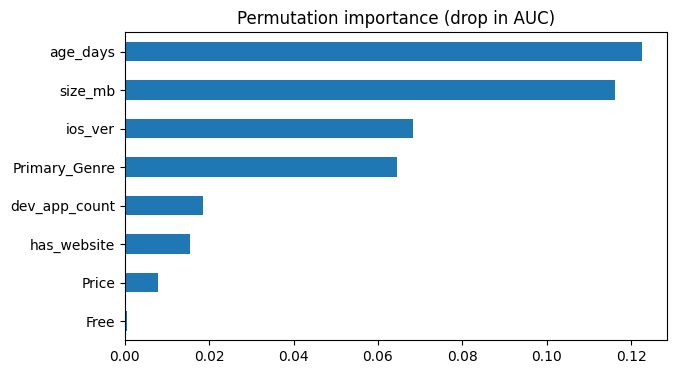

In [0]:
imp = permutation_importance(model, Xte, yte, scoring="roc_auc", n_repeats=5, random_state=42)
imp_df = pd.Series(imp.importances_mean, index=X.columns).sort_values()
imp_df.plot.barh(figsize=(7, 4), title="Permutation importance (drop in AUC)")
plt.show()

## 10. ทดสอบสมมติฐานทางสถิติ
**ทำอะไร:** เปรียบเทียบดาวเฉลี่ยของสามคู่กลุ่ม (เฉพาะแอปที่มีรีวิว สุ่ม 20%)

| คู่เปรียบเทียบ | คำถาม |
|---|---|
| ฟรี vs เสียเงิน | แอปฟรีได้ดาวต่างจากแอปเสียเงินหรือไม่ |
| มีเว็บไซต์ vs ไม่มี | นักพัฒนาที่มีเว็บไซต์ได้ดาวต่างกันหรือไม่ |
| นักพัฒนารายใหญ่ (มากกว่า 10 แอป) vs รายเดี่ยว (1 แอป) | รายใหญ่ได้ดาวสูงกว่าหรือไม่ |

**วัดยังไง:**
- **Mann-Whitney U test** เพราะดาวไม่ได้กระจายแบบปกติ ให้ค่า p-value
- **ผลต่างของดาวเฉลี่ย** บอกขนาดผลในหน่วยที่เข้าใจง่าย
- **Cliff's delta** ขนาดผล (effect size) ตั้งแต่ -1 ถึง 1 เกณฑ์คร่าว ๆ คือ ราว 0.15 เล็ก, 0.33 กลาง, 0.47 ใหญ่

**อ่านผล:** ข้อมูลมีหลายแสนแถว p-value จึงเล็กมากเกือบทุกกรณี แม้ผลจริงเล็กจนไม่มีความหมาย ให้ตัดสินจาก Cliff's delta และผลต่างของดาวเป็นหลัก

In [0]:
from scipy.stats import mannwhitneyu

s = (clean.where("Reviews > 0").select("Average_User_Rating", "Free", "has_website", "dev_app_count")
     .sample(fraction=0.2, seed=1).toPandas())

def test(a, b, name):
    u, p = mannwhitneyu(a, b, alternative="two-sided")
    cliff = 2 * u / (len(a) * len(b)) - 1
    print(f"{name}: p={p:.2e}, mean diff={a.mean() - b.mean():+.3f} stars, Cliff's delta={cliff:+.3f}")

test(s[s.Free == True].Average_User_Rating, s[s.Free == False].Average_User_Rating, "Free vs Paid (rating)")
test(s[s.has_website == 1].Average_User_Rating, s[s.has_website == 0].Average_User_Rating, "Has website vs none (rating)")
test(s[s.dev_app_count > 10].Average_User_Rating, s[s.dev_app_count == 1].Average_User_Rating, "Big dev vs indie (rating)")

Free vs Paid (rating): p=2.37e-151, mean diff=+0.317 stars, Cliff's delta=+0.157
Has website vs none (rating): p=2.33e-14, mean diff=+0.142 stars, Cliff's delta=+0.026
Big dev vs indie (rating): p=0.00e+00, mean diff=-0.490 stars, Cliff's delta=-0.265


## 11. ตารางสรุปสำหรับทำเว็บ
**ทำอะไร:** ยุบข้อมูล 1.2 ล้านแถวเป็นตารางสรุปขนาดเล็ก (ราวหมื่นแถว) ให้หน้าเว็บโหลดและกรองได้เร็วโดยไม่ต้องต่อ Databricks

**วัดยังไง:** จัดกลุ่มตามปีเปิดตัว, หมวด, ฟรี/เสียเงิน, ช่วงขนาด และขนาดนักพัฒนา แล้วเก็บผลรวมของจำนวนแอป แอปที่มีรีวิว แอปที่ติดตลาด แอปร้าง รีวิวรวม และผลรวมดาว หน้าเว็บคำนวณเปอร์เซ็นต์เองจากผลรวมเหล่านี้

**วิธีดาวน์โหลด:** กดไอคอนดาวน์โหลดที่ผลลัพธ์ เลือก **Download full results** (ถ้าเลือกแบบแสดงผล จะได้แค่ 10,000 แถวแรก)

In [0]:
%sql
SELECT release_year, Primary_Genre, Free,
       CASE WHEN size_mb IS NULL THEN 'unknown'
            WHEN size_mb < 10  THEN '<10 MB'
            WHEN size_mb < 50  THEN '10-50 MB'
            WHEN size_mb < 100 THEN '50-100 MB'
            WHEN size_mb < 500 THEN '100-500 MB'
            ELSE '500+ MB' END AS size_bucket,
       CASE WHEN dev_app_count = 1   THEN 'indie'
            WHEN dev_app_count <= 10  THEN '2-10 apps'
            WHEN dev_app_count <= 100 THEN '11-100 apps'
            ELSE '100+ apps' END AS dev_size,
       COUNT(*) AS apps,
       SUM(CASE WHEN Reviews > 0 THEN 1 ELSE 0 END) AS with_reviews,
       SUM(CASE WHEN Reviews > 1000 THEN 1 ELSE 0 END) AS hits,
       SUM(is_zombie) AS zombies,
       SUM(Reviews) AS total_reviews,
       SUM(CASE WHEN Reviews > 0 THEN Average_User_Rating END) AS rating_sum
FROM apps
WHERE release_year BETWEEN 2008 AND 2021
GROUP BY ALL;

release_year,Primary_Genre,Free,size_bucket,dev_size,apps,with_reviews,hits,zombies,total_reviews,rating_sum
2019,Health & Fitness,true,<10 MB,11-100 apps,67,13,0,43,36,45.36667
2015,Entertainment,true,10-50 MB,11-100 apps,654,392,13,523,42732,1322.64042
2012,Music,false,<10 MB,11-100 apps,33,24,0,25,386,67.11781
2013,Productivity,false,<10 MB,2-10 apps,93,52,1,65,5315,186.13231000000002
2019,Music,true,10-50 MB,2-10 apps,563,308,3,343,5918463,1328.8751399999999
2019,Productivity,true,10-50 MB,2-10 apps,2352,649,18,1216,289982,2643.5827
2017,Medical,true,50-100 MB,11-100 apps,88,43,0,62,1586,169.93567000000002
2009,Education,true,10-50 MB,2-10 apps,40,40,3,27,29874,140.96988000000002
2020,Utilities,true,50-100 MB,2-10 apps,2272,631,21,185,152087,2582.41595
2015,Utilities,true,50-100 MB,11-100 apps,118,70,3,81,10880,232.85304999999997


## 12. ข้อจำกัดของการวิเคราะห์
- ข้อมูลเป็น **snapshot** ครั้งเดียว ไม่มีประวัติการเปลี่ยนแปลงของแอปแต่ละตัว จึงบอกไม่ได้ว่าการเปลี่ยนแปลงใดเป็นสาเหตุ
- ไม่มีข้อมูลอันดับ การถูก feature หรือ algorithm ของ Apple จึงสรุปเรื่อง algorithm ไม่ได้
- ไม่มียอดดาวน์โหลด ใช้จำนวนรีวิวเป็นตัวแทนความนิยม ซึ่งไม่เท่ากับจำนวนผู้ใช้
- แอปรุ่นใหม่มีเวลาสะสมรีวิวน้อยกว่าแอปรุ่นเก่า การเทียบข้ามรุ่นปีจึงต้องระวัง
- ผลทั้งหมดเป็นความสัมพันธ์ ไม่ใช่ความเป็นเหตุเป็นผล
- `Current_Version_Score` ไม่ต่างจาก `Average_User_Rating` ในข้อมูลนี้ จึงสร้างตัวแปรแนวโน้มคะแนนไม่ได้
- `Current_Version_Reviews` เท่ากับ `Reviews` ทุกแถว จึงแยกไม่ได้ว่าแอปยังได้รีวิวใหม่อยู่ หรือเคยดังแล้วเงียบไป
- **วันอ้างอิงน่าจะช้ากว่าความจริง:** `ref_date` = `max(Updated)` = 2022-04-09 แต่มีแอปที่อัปเดตหลังกลาง ต.ค. 2021 แค่ 288 แอป และไฟล์ลงวันที่ 14 ต.ค. 2021 วันเก็บข้อมูลจริงจึงน่าจะราวกลาง ต.ค. 2021 ผลคือ `age_days` และ `days_since_update` สูงกว่าจริงราว 6 เดือนทุกแอป เกณฑ์แอปร้าง 730 วันเทียบกับวันจริงจึงเท่ากับไม่อัปเดตราว 1.5 ปี notebook นี้คงค่าเดิมไว้เพื่อให้ผลทุกหัวข้อเทียบกันได้